<a href="https://colab.research.google.com/github/mbravoar/hello-world/blob/main/HW5_ANN_Long.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Importing all the libraries and functions needed for the code
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import io
import seaborn as sns
import re

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.optimizers import RMSprop
from scipy import stats
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import LabelEncoder


In [ ]:
#Function to load to Google Collab the dataset
from google.colab import files
uploaded = files.upload()

Saving Dataset for Fracture and Impact Toughness of High-Entropy Alloys_v3_modified.xlsx to Dataset for Fracture and Impact Toughness of High-Entropy Alloys_v3_modified.xlsx


In [ ]:
# Reading the file with the data uploaded and saving it in a dataframe
file_path = "Dataset for Fracture and Impact Toughness of High-Entropy Alloys_v3_modified.xlsx"  # Change to your actual file path
sheet_name = "Fracture toughness"  # Replace with the sheet name you want to load
df = pd.read_excel(file_path, sheet_name=sheet_name)
df = df.drop(columns=['ID','Reference','Publication date','JQ (kJ/m2)','KQ (MPa·m1/2)','Composition from the references','Composition (at. %)','JIC (kJ/m2)','Uniform (plastic) elongation (%)'])

df.head()  # Show the first few rows

,Material condition,Processing history,Phase,Grain size (um),Density (g/cm3),Hardness (HV),Hardness (GPa),Youngs modulus (GPa),Tensile YS (MPa),UTS (MPa),Final elongation (%),Testing temperature (K),Test type (K or J),Standard followed,Sample geomtry,Sample size (mm),Notch geometry (mm),KIC (MPa·m1/2)
0,as-synthesized,laser-solidified,B2+matrensite,NaN,NaN,NaN,11.3,187.1,NaN,NaN,NaN,298,K,NaN,indentation,NaN,NaN,50.9
1,as-synthesized,laser-solidified,B2,NaN,NaN,NaN,7.5,117.9,NaN,NaN,NaN,298,K,NaN,indentation,NaN,NaN,7.6
2,as-cast,VIM,BCC+B2,NaN,NaN,NaN,5.34±0.07,NaN,NaN,NaN,NaN,298,K,ASTM E399-12,SENB,30*6*3,straight [3(depth)],5.8±0.2
3,as-cast,VIM,BCC+B2,NaN,NaN,NaN,5.34±0.07,NaN,NaN,NaN,NaN,298,K,ASTM E1304-97,CVNRB,30*6*4,chevron [0.3(depth) & 60°(angle)],5.4±0.2
4,annealed,arc-melted + cold-forged and cross-rolled (~60...,FCC,6,NaN,NaN,NaN,202,410±21,763±32,57±7,293,J,ASTM E1820 (10),C(T),18(W)*9(B),straight [0.1(root radius)*6.6(depth)],217


In [ ]:
"""
Many values on the data frame have a tolerance. This function helps to drop that tolerance and just keep the nominal value.
"""
def extract_number(value):
    value = str(value)
    if pd.isnull(value) or value == "":
        return float('nan')
    else:
        # Modified regex to handle hyphens and potential spaces around them
        match = re.search(r'([\d.]+)\s*[-–]\s*([\d.]+)?', value)
        if match:
            # If range found, return the first number (lower bound) as float
            return float(match.group(1))
        else:
            # If no range, try to convert to float as before
            try:
                return float(re.split(r'±|\+/-', value)[0])
            except ValueError:
                # Handle cases that still can't be converted
                return float('nan')
# List of columns to process
columns_to_process = ['Grain size (um)', 'Density (g/cm3)','Hardness (HV)','Hardness (GPa)','Youngs modulus  (GPa)','Tensile YS (MPa)','UTS (MPa)','Final elongation (%)','KIC (MPa·m1/2)']

# Apply the function to each column
for column in columns_to_process:
    df[column] = df[column].apply(extract_number)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Material condition       153 non-null    object 
 1   Processing history       153 non-null    object 
 2   Phase                    150 non-null    object 
 3   Grain size (um)          57 non-null     float64
 4   Density (g/cm3)          24 non-null     float64
 5   Hardness (HV)            65 non-null     float64
 6   Hardness (GPa)           21 non-null     float64
 7   Youngs modulus  (GPa)    32 non-null     float64
 8   Tensile YS (MPa)         27 non-null     float64
 9   UTS (MPa)                24 non-null     float64
 10  Final elongation (%)     21 non-null     float64
 11  Testing temperature (K)  153 non-null    int64  
 12  Test type (K or J)       150 non-null    object 
 13  Standard followed        67 non-null     object 
 14  Sample geomtry           1

In [ ]:
#Columns with info that don´t have numerical values area dropped
df = df.drop(columns=['Material condition','Processing history','Phase','Testing temperature (K)','Test type (K or J)','Standard followed','Sample geomtry','Sample size (mm)','Notch geometry (mm)'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Grain size (um)        57 non-null     float64
 1   Density (g/cm3)        24 non-null     float64
 2   Hardness (HV)          65 non-null     float64
 3   Hardness (GPa)         21 non-null     float64
 4   Youngs modulus  (GPa)  32 non-null     float64
 5   Tensile YS (MPa)       27 non-null     float64
 6   UTS (MPa)              24 non-null     float64
 7   Final elongation (%)   21 non-null     float64
 8   KIC (MPa·m1/2)         136 non-null    float64
dtypes: float64(9)
memory usage: 10.9 KB


In [ ]:
# Drop any row/Data entry with all columns with NaN values
df = df.dropna(how='all')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 151 entries, 0 to 152
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Grain size (um)        57 non-null     float64
 1   Density (g/cm3)        24 non-null     float64
 2   Hardness (HV)          65 non-null     float64
 3   Hardness (GPa)         21 non-null     float64
 4   Youngs modulus  (GPa)  32 non-null     float64
 5   Tensile YS (MPa)       27 non-null     float64
 6   UTS (MPa)              24 non-null     float64
 7   Final elongation (%)   21 non-null     float64
 8   KIC (MPa·m1/2)         136 non-null    float64
dtypes: float64(9)
memory usage: 11.8 KB


In [ ]:
# List of columns to apply mode imputation
columns_to_impute = ['Grain size (um)', 'Density (g/cm3)','Hardness (HV)','Hardness (GPa)','Youngs modulus  (GPa)','Tensile YS (MPa)','UTS (MPa)','Final elongation (%)','KIC (MPa·m1/2)']

# Apply mode imputation to each column
for column in columns_to_impute:
    df[column] = df[column].fillna(df[column].mode()[0])

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 151 entries, 0 to 152
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Grain size (um)        151 non-null    float64
 1   Density (g/cm3)        151 non-null    float64
 2   Hardness (HV)          151 non-null    float64
 3   Hardness (GPa)         151 non-null    float64
 4   Youngs modulus  (GPa)  151 non-null    float64
 5   Tensile YS (MPa)       151 non-null    float64
 6   UTS (MPa)              151 non-null    float64
 7   Final elongation (%)   151 non-null    float64
 8   KIC (MPa·m1/2)         151 non-null    float64
dtypes: float64(9)
memory usage: 11.8 KB


<Axes: >

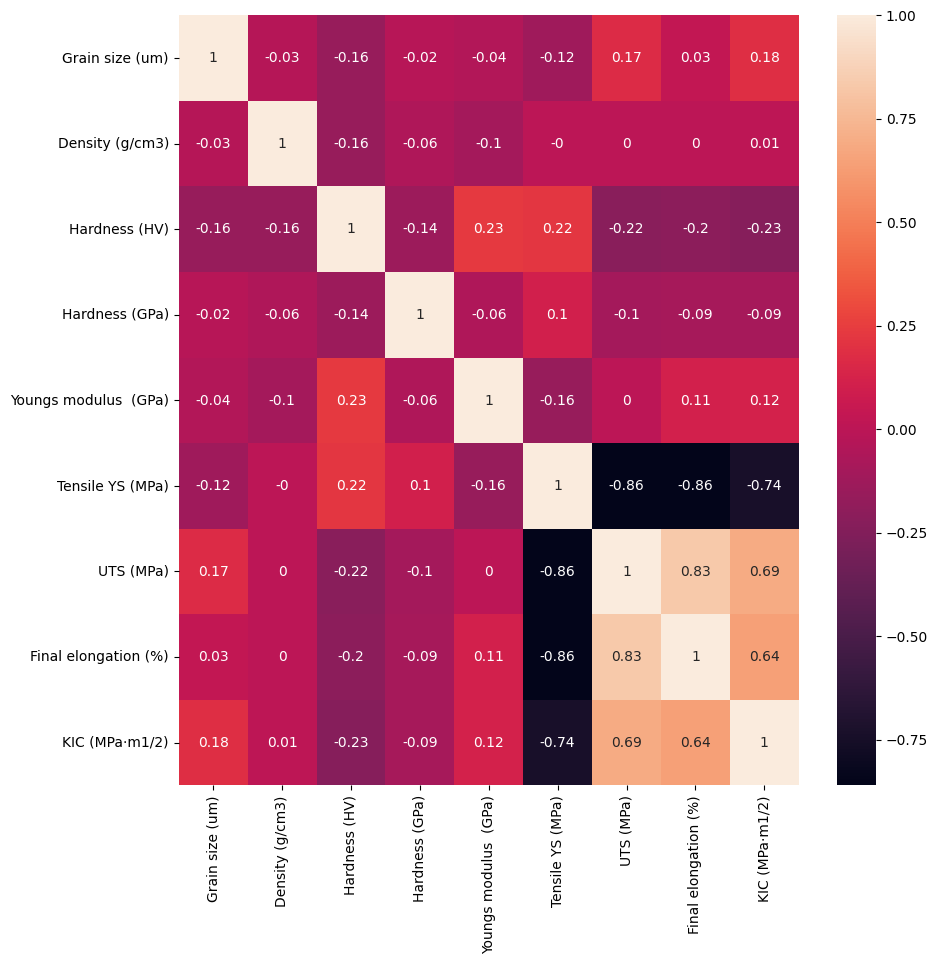

In [ ]:
#Correlation Heatmap for the provided data
plt.figure(figsize = (10, 10))
sns.heatmap(df.corr().round(2), annot = True)

In [ ]:
#Some columns showed colinearity. Those are dropped from the data set.
df = df.drop(columns=['UTS (MPa)','Final elongation (%)','Hardness (HV)','Youngs modulus  (GPa)'])
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 151 entries, 0 to 152
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Grain size (um)   151 non-null    float64
 1   Density (g/cm3)   151 non-null    float64
 2   Hardness (GPa)    151 non-null    float64
 3   Tensile YS (MPa)  151 non-null    float64
 4   KIC (MPa·m1/2)    151 non-null    float64
dtypes: float64(5)
memory usage: 7.1 KB


<Axes: >

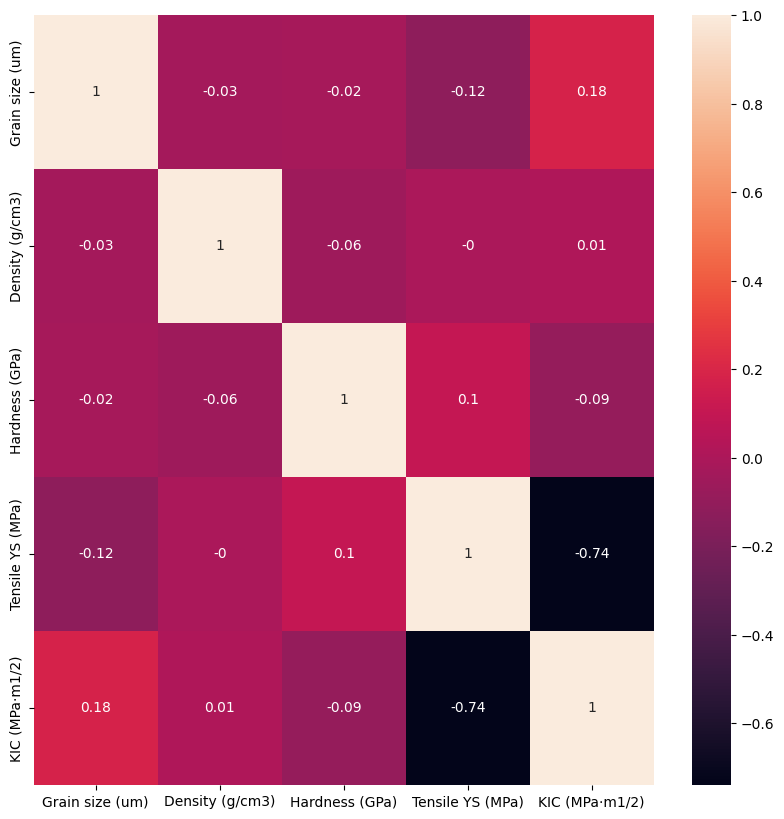

In [ ]:
#Correlation Heatmap for the provided data after dropping variables with colinearity
plt.figure(figsize = (10, 10))
sns.heatmap(df.corr().round(2), annot = True)

In [ ]:
#Just cheking the shape of the dataframe. Number of columns and number of datapoints.
df.shape

(151, 5)

In [ ]:
#Dividing the df into Input variables and Target variable
X=df.drop(columns=['KIC (MPa·m1/2)'])  # Input variable
y = df['KIC (MPa·m1/2)']  # Target variable

In [ ]:
#Standarization of the Input variables
scaler = StandardScaler()
X_scaled= scaler.fit_transform(X)

In [ ]:
#Splitting the df into Tranning and Testing sets. test_size variable defines the lenght of the Testing sample
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.75)#, random_state=17)

In [ ]:
#Checking size of the trainning sample
X_train.shape

(37, 4)

In [ ]:
#Checking size of the testing sample
X_test.shape

(114, 4)

In [ ]:
# Define the neural network model
def create_ann():
    model = Sequential([
        Dense(8, activation='relu', input_shape=(4,)),  # First  layer with 8 neurons. The ANN recieves 3 inputs.
        Dense(16, activation='relu'),  # Third hidden layer with 16 neurons
        Dense(32, activation='relu'),  # Third hidden layer with 32 neurons
        Dense(16, activation='relu'),  # Third hidden layer with 16 neurons
        Dense(1, activation='linear')  # Output layer with 1 neuron. The ANN outputs 1 value.
    ])

    # Set the learning rate at 0.001
    learning_rate = 0.001
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

    # Compiling the ANN model and setting as metric MSE
    model.compile(optimizer=optimizer, loss='mse', metrics=['mse'])  # Track MSE
    return model

In [ ]:
# Creating the ANN model
model = create_ann()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Display model summary
#model.summary()

In [ ]:
# This function has the intention of storing the MSE value to later plot it.
class MSECallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        mse = logs.get('mse')
        self.mse_history.append(mse)

    def on_train_begin(self, logs=None):
        self.mse_history = []

In [ ]:
# Initiating the MSE Storing function
mse_callback = MSECallback()

In [ ]:
# Funtion to early stop the trainning if MSE does not improves for 10 consecutive iterations.
early_stopping = EarlyStopping(monitor='mse', patience=10, verbose=1)

In [ ]:
"""
Train the model and track MSE at each epoch with early stopping
The trainning is set to perform 500 iterations for modifiying the weights
"""

model.fit(X_train,y_train, epochs=500, batch_size=16, verbose=1,callbacks=[mse_callback, early_stopping])

Epoch 1/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 6016.4209 - mse: 6016.4209
Epoch 2/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 5634.1245 - mse: 5634.1245
Epoch 3/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 9303.4941 - mse: 9303.4941  
Epoch 4/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 9352.2490 - mse: 9352.2490  
Epoch 5/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 5326.2202 - mse: 5326.2202
Epoch 6/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 8800.5273 - mse: 8800.5273  
Epoch 7/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 5588.2451 - mse: 5588.2451
Epoch 8/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 4431.4819 - mse: 4431.4819 
Epoch 9/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 9416.3320 - mse: 9416.3320  
Epoch 10/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 6106.3716 - mse: 6106.3716
Epoch 11/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 3873.0598 - mse: 3873.0598
Epoch 12/500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - l

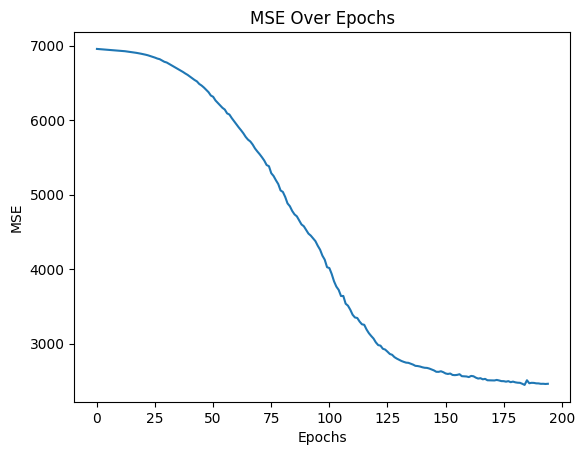

In [ ]:
# Plotting the behaviour of MSE during trainning iterations
plt.plot(mse_callback.mse_history)
plt.title('MSE Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.show()

In [ ]:
# Making predictions for the Trainning set
predictions = model.predict(X_train)
rounded_predictions = np.round(predictions, 3)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


In [ ]:
# Make predictions for the Testing set
new_predictions = model.predict(X_test)
rounded_predictions = np.round(new_predictions, 3)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


Text(0, 0.5, 'y_real')

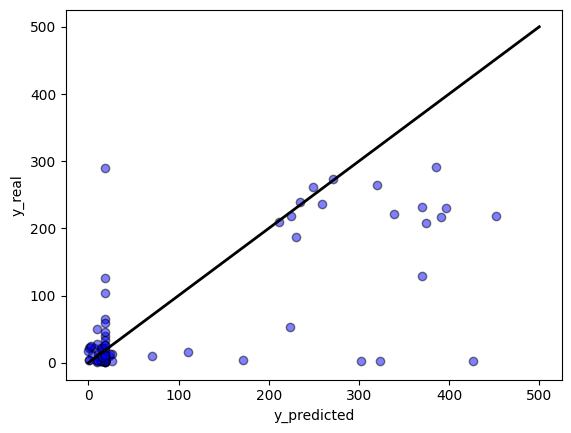

In [ ]:
"""
# Creating a correlation plot for the Testing Sample
X axis is the predicted Stress values
Y axis is the real Stress values
"""
plt.scatter(new_predictions, y_test, color='blue', alpha=0.5, edgecolors='black')
# Adding the perfect correlation line Real values=Predicted values
plt.plot([0, 500], [0, 500], color='black', linewidth=2, label="y = x")
plt.xlabel("y_predicted")
plt.ylabel("y_real")

Text(0, 0.5, 'y_real')

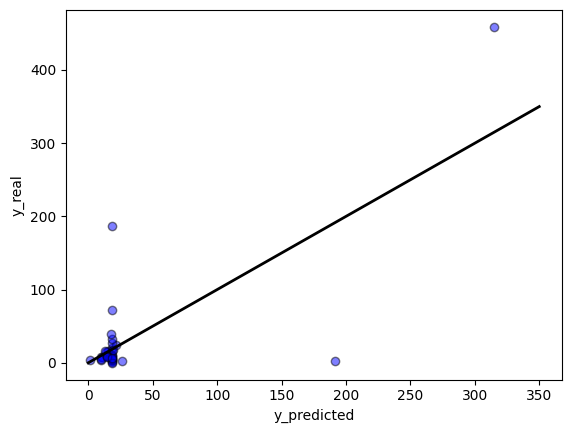

In [ ]:
"""
# Creating a correlation plot for the Trainning Sample
X axis is the predicted Stress values
Y axis is the real Stress values
"""
plt.scatter(predictions, y_train, color='blue', alpha=0.5, edgecolors='black')
# Adding the perfect correlation line Real values=Predicted values
plt.plot([0, 350], [0, 350], color='black', linewidth=2, label="y = x")
plt.xlabel("y_predicted")
plt.ylabel("y_real")

In [ ]:
#Evaluating the performance of the ANN with different metrics (MSE, RMSE, MAE and R2)
mse = mean_squared_error(y_test, new_predictions)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, new_predictions)
r2 = r2_score(y_test, new_predictions)

print(f"MSE: {mse:.2f}, RMSE: {rmse:.2f}, MAE: {mae:.2f}, R²: {r2:.2f}")

MSE: 7008.74, RMSE: 83.72, MAE: 39.96, R²: -0.07


In [ ]:
#Line to clear the ANN memory
tf.keras.backend.clear_session()